In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## error-bar-plot

**Figure 2: Average GLUE accuracy of five fine-tuning methods.** Points show the mean over 5 seeds and error bars ±1 std. Ours reaches 0.879, ahead of full fine-tuning (0.865) by 0.014, about three times the spread over seeds (std ≤ 0.005).

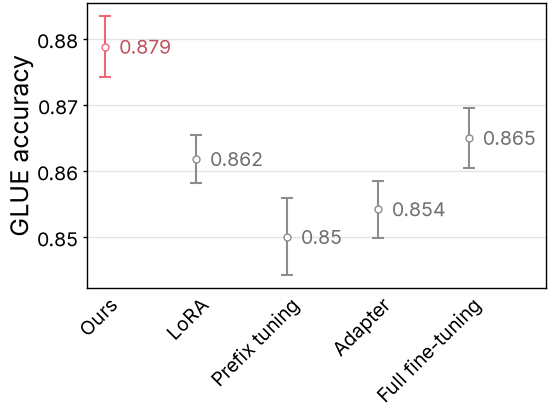

In [2]:
with open("../data/error-bar-plot.json") as f:
    accuracy_per_seed = json.load(f)["accuracy_per_seed"]

methods = list(accuracy_per_seed)
fig, ax = plt.subplots(figsize=(2.75, 2))
for x, method in enumerate(methods):
    mean = np.mean(accuracy_per_seed[method])
    std = np.std(accuracy_per_seed[method], ddof=1)
    color = colors["ours"] if method == "Ours" else colors["neutral"]
    ax.errorbar(x, mean, yerr=std, fmt="o", color=color, capsize=2, elinewidth=0.75, capthick=0.75)
    ax.annotate(f"{mean:.3g}", (x, mean), xytext=(5, 0), textcoords="offset points", va="center", color=darken(color))
ax.set_xticks(range(len(methods)), labels=methods, rotation=45, ha="right", rotation_mode="anchor")
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("GLUE accuracy")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/error-bar-plot.pdf")
fig.savefig("../outputs/error-bar-plot.png")
plt.show()